In [1]:
import tensorflow as tf

In [3]:
import numpy as np
from tensorflow import keras
import pathlib
import matplotlib.pyplot as plt

In [ ]:
Aqui vamos criar uma rede neural piramide, multineural, com 3 camadas 32, 16, 1 - decrescente

In [4]:
model = keras.Sequential([
    keras.layers.Dense(units = 32, activation='relu', input_shape = [1]),
    keras.layers.Dense(units = 16, activation = 'relu'),
    keras.layers.Dense(units = 1)
])

c:\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
#3) compilando o modelo
model.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609 (2.38 KB)

 Trainable params: 609 (2.38 KB)

 Non-trainable params: 0 (0.00 B)

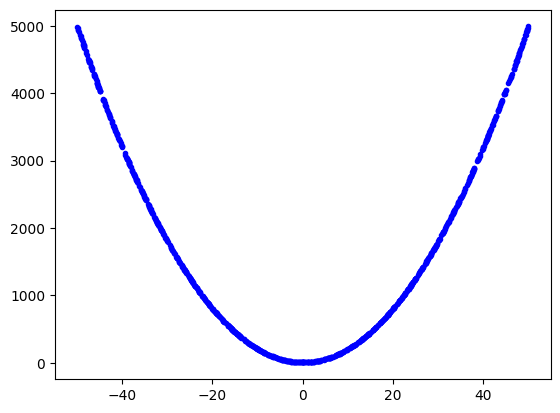

In [6]:
#vamos construir um conjunto de dados para a função y = 2x² +3
#vamos corrigir o número de dados que irão compor o dataset
num_samples = 1000
#uam vez que vamos gerar números aleatórios, é aconselhavel fixar uma semente
seed = 1337
#iniciar o gerador de numeros aleatorios usando o seed
np.random.seed(seed)
tf.random.set_seed(seed)
#vamos construir uma matriz xs de números aleatorios num_samples entre um valor min -50 +50
xs = np.random.uniform(low=-50, high=50, size =num_samples)
#embaralhe
np.random.shuffle(xs)
#calcular o valor de y correspondente a partir da funcao conhecida  y = 2x²+0x +3
ys = 2 * xs*xs +3 #matriz de saida
#vamos plotar o resultado
plt.plot(xs, ys, 'b.')
plt.show()

In [7]:
#fazer o modelo aprender
model.fit(xs, ys, epochs = 1000)

Epoch 1/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 5050542.5000 - mae: 1684.2059   
Epoch 2/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5010441.0000 - mae: 1676.1335
Epoch 3/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4960258.0000 - mae: 1665.9681 
Epoch 4/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4890220.0000 - mae: 1651.6272 
Epoch 5/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4784495.5000 - mae: 1629.7418 
Epoch 6/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 647us/step - loss: 4628546.5000 - mae: 1597.0334
Epoch 7/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4411254.0000 - mae: 1550.6193 
Epoch 8/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4124398.2500 - mae: 1487.9133 
Epoch 9/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3767489.7500 - mae: 1407.3832 
Epoch 10/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3349359.2500 - mae: 1309.2754 
Epoch 11/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2887741.5000 - mae: 1196.3

In [8]:
#predicao deexemplo com x= 10.0
print("Predição com x= 10.0:", model.predict(np.array([[10.0]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Predição com x= 10.0: [[203.79205]]


In [9]:
#8)exportar no formato saved_model
saved_dir = 'saved_model/2' #diretorio
model.export(saved_dir) #exportar o modelo em SavedModel compativel com TF
print(f"Modelo  exportado no formato SavedModel em: {pathlib.Path(saved_dir).resolve()}")

INFO:tensorflow:Assets written to: saved_model/2\assets


INFO:tensorflow:Assets written to: saved_model/2\assets


Saved artifact at 'saved_model/2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2132442335184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132442337296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132442337680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132442337104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132442339216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132442336912: TensorSpec(shape=(), dtype=tf.resource, name=None)
Modelo  exportado no formato SavedModel em: C:\Users\iango\OneDrive\Desktop\tinyml\saved_model\2


In [12]:
#calculo da ocupação de memoria do modelo salvo
import os
def get_dir_size(saved_dir):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(saved_dir):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            total_size += os.path.getsize(fp)
    return total_size

file_size_savedmodel = get_dir_size(saved_dir)
print(f"Tamanho do modelo SavedModel: {file_size_savedmodel:.2f} bytes")

Tamanho do modelo SavedModel: 50998.00 bytes


In [14]:
#configuração para converter para TFlite
converter = tf.lite.TFLiteConverter.from_saved_model(saved_dir) #cria o conversor
converter.experimental_enable_resource_variables = True #habilita o uso de variaveis de recurso
tflite_model = converter.convert() #converte o modelo

In [15]:
#10) salvar o modelo TFlite em disco
tflite_path = pathlib.Path('model_from_savedmodel2.tflite')
tflite_path.write_bytes(tflite_model)
print(f"Modelo TFLite salvo em: {tflite_path.resolve()}")   
print(f"Tamanho do modelo TFLite: {tflite_path.stat().st_size} bytes")

Modelo TFLite salvo em: C:\Users\iango\OneDrive\Desktop\tinyml\model_from_savedmodel2.tflite
Tamanho do modelo TFLite: 4300 bytes


In [16]:
#11) Inicialização do interpretador TFlite 
interpreter = tf.lite.Interpreter(model_path=str(tflite_path)) #carrega o model tflite
interpreter.allocate_tensors() #aloca memoria para tensores


c:\Python312\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [17]:
#12) obter detalhes dos tensores de entrada e saída
input_details = interpreter.get_input_details() #metadados do tensor de entrada
output_details = interpreter.get_output_details() #metadados do tensor de saída
print("Input detalhes:", input_details)
print("Output detalhes:", output_details)

Input detalhes: [{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
Output detalhes: [{'name': 'StatefulPartitionedCall_1:0', 'index': 9, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]


In [18]:
#13) execução da inferencia tflite
to_predict = np.array([[10.0]], dtype = np.float32) #dados de entrada para predição
interpreter.set_tensor(input_details[0]['index'], to_predict) #definir o tensor de entrada
interpreter.invoke() #executar a inferencia
tflite_results = interpreter.get_tensor(output_details[0]['index']) #extrair o resultado
print("Predição TFlite com x=10.0:", tflite_results)


Predição TFlite com x=10.0: [[203.792]]
